In [1]:
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

Первичный анализ

In [3]:
df = pd.read_csv("bank.csv")
print(f"Размер датасета: {df.shape[0]} клиентов и {df.shape[1]} признаков")
print(df.columns)
df = df.drop(["day"], axis=1)

economic_stats = df.groupby("job")[["balance", "duration"]].mean()
print("\nСредний баланс и возраст по профессии:\n", economic_stats)

# ! Если у вас признак 0 - 1 записан строкой да - нет
df["deposit"] = df["deposit"].map({"yes": 1, "no": 0})


print("\nПервые 3 строки очищенных данных")
display(df.head(3))
df.info()

Размер датасета: 11162 клиентов и 17 признаков
Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='str')

Средний баланс и возраст по профессии:
                    balance    duration
job                                   
admin.         1195.866567  347.929535
blue-collar    1203.926440  394.658951
entrepreneur   1621.942073  370.182927
housemaid      1366.160584  348.346715
management     1793.663679  361.482073
retired        2417.250643  389.993573
self-employed  1865.372840  396.155556
services       1081.171181  385.955580
student        1500.783333  330.672222
technician     1556.294569  363.791552
unemployed     1314.719888  422.843137
unknown        1945.457143  330.371429

Первые 3 строки очищенных данных


,age,job,marital,education,default,balance,housing,loan,contact,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,may,1042,1,-1,0,unknown,1
1,56,admin.,married,secondary,no,45,no,no,unknown,may,1467,1,-1,0,unknown,1
2,41,technician,married,secondary,no,1270,yes,no,unknown,may,1389,1,-1,0,unknown,1


<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   month      11162 non-null  str  
 10  duration   11162 non-null  int64
 11  campaign   11162 non-null  int64
 12  pdays      11162 non-null  int64
 13  previous   11162 non-null  int64
 14  poutcome   11162 non-null  str  
 15  deposit    11162 non-null  int64
dtypes: int64(7), str(9)
memory usage: 1.4 MB


был удален столбец day, целевая переменная deposit преобразована в числовой формат, рассчитаны средний баланс и длительность контакта по профессиям. В результате получено 11162 записи и 16 признаков без пропущенных значений. Группировка данных по профессиям показала различия в среднем балансе и длительности контакта: наибольший средний баланс выявлен у пенсионеров, а наименьший - у работников сферы услуг. Наибольшая средняя длительность контакта отмечается у безработных, а наименьшая у студентов. 

Разведочный анализ/визуализация 

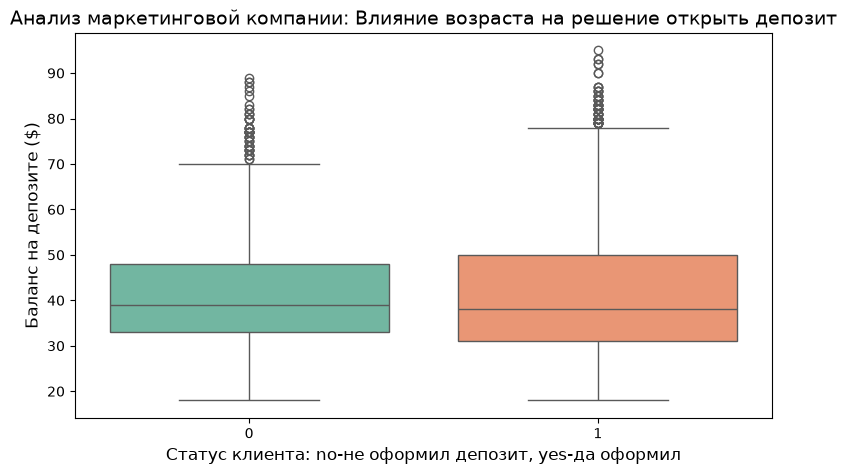

In [4]:
plt.figure(figsize=(9,5))
sns.boxplot(x="deposit", y="age", data=df, palette="Set2", legend=False, hue="deposit")
plt.title("Анализ маркетинговой компании: Влияние возраста на решение открыть депозит", fontsize=14)
plt.xlabel("Статус клиента: no-не оформил депозит, yes-да оформил", fontsize=12)
plt.ylabel("Баланс на депозите ($)", fontsize=12)
plt.show() 

На графике видно, что распределение баланса на депозите у клиентов, оформивших и не оформивших депозит практически схоже. Медианные значения в целом одинаковы и состовляют около 38-39 долларов. При этом у клиентов, оформивших депозит, наблюдается немного больший разброс значений баланса. Поэтому, по одному только балансу нельзя точно разделить клиентов на тех, кто оформил депозит и тех, кто отказался от него 

In [5]:
X = pd.get_dummies(df.drop("deposit", axis=1), columns=["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"], drop_first=True)

y = df["deposit"]
print("Категориальные признаки переведы в бинарный вид")
X.head(3)

Категориальные признаки переведы в бинарный вид


,age,balance,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,59,2343,1042,1,-1,0,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,56,45,1467,1,-1,0,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
2,41,1270,1389,1,-1,0,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True


Категориальные признаки были переведены в бинарный формат с помощью pd.get_dummies(). В результате текстовые значения категорий заменены на отдельные столбцы со значениями True и False, что позволяет использовать данные для обучения моделей машинного обучения. После преобразования таблица содержит 41 признак, а целевая переменная deposit сохранена отдельно.

Масштабирование

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

number_cols = ["age",
               "balance",
               "duration",
               "pdays",
               "campaign",
               "previous"]

scaler = StandardScaler()

X_train[number_cols] = scaler.fit_transform(X_train[number_cols])
# только transform, чтобы модель не подглядывала
X_test[number_cols] = scaler.transform(X_test[number_cols])
X_train.head(3)

,age,balance,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
8644,0.412051,-0.321431,-0.343988,0.178481,-0.484037,-0.355931,False,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2632,0.412051,0.359538,-0.317972,-0.540031,0.386954,3.075684,False,False,False,False,...,False,False,False,False,False,False,True,False,True,False
3056,-1.356310,-0.451508,-0.485632,-0.540031,0.359449,0.073021,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


Числовые признаки age, balance, duration, campaign, pdays, previous были стандартизированы с помощью StandardScaler. Значения признаков переведены к единому масштабу: среднее значение каждого признака в обучающей выборке близко к нулю, а стандартное отклонение к единице. 

In [ ]:
print(X_train.select_dtypes(include="object").columns)
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred) * 100

print(f"Общая точность модели (Accuracy): {accuracy:.2f}%\n")

Index([], dtype='str')
Общая точность модели (Accuracy): 85.80%



В итоге модель была обучена модель классификации RandomForestClassifier со 100 деревьями и сбалансированными весами классов. Для оценки качества модели использовалась общая точность Accuracy, которая составила 85.80%. Это означает, что модель правильно классифицировала примерно 86% объектов текстовой выборки.